In [11]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from prob_reco_sbi.flash import load

# Locate the project root（定位项目根目录）
ROOT = Path.cwd()
if not (ROOT / "data" / "t3_straight.h5").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data"
OUT = ROOT / "figures"
OUT.mkdir(exist_ok=True)

# Define six physics modes（定义六种物理模式）
modes = [
    "straight",
    "absorb",
    "absorb-scatter",
    "full",
    "straight_scattering",
    "straight_reflection"
]

# Load datasets with 20,000 events（加载包含20000个事件的数据集）
datasets = {}

for mode in modes:
    file = DATA / f"t3_{mode}.h5"
    datasets[mode] = load(file, hits=False, tracks=False)
    print(mode, datasets[mode].response.charge.shape)

straight (20000, 32)
absorb (20000, 32)
absorb-scatter (20000, 32)
full (20000, 32)
straight_scattering (20000, 32)
straight_reflection (20000, 32)


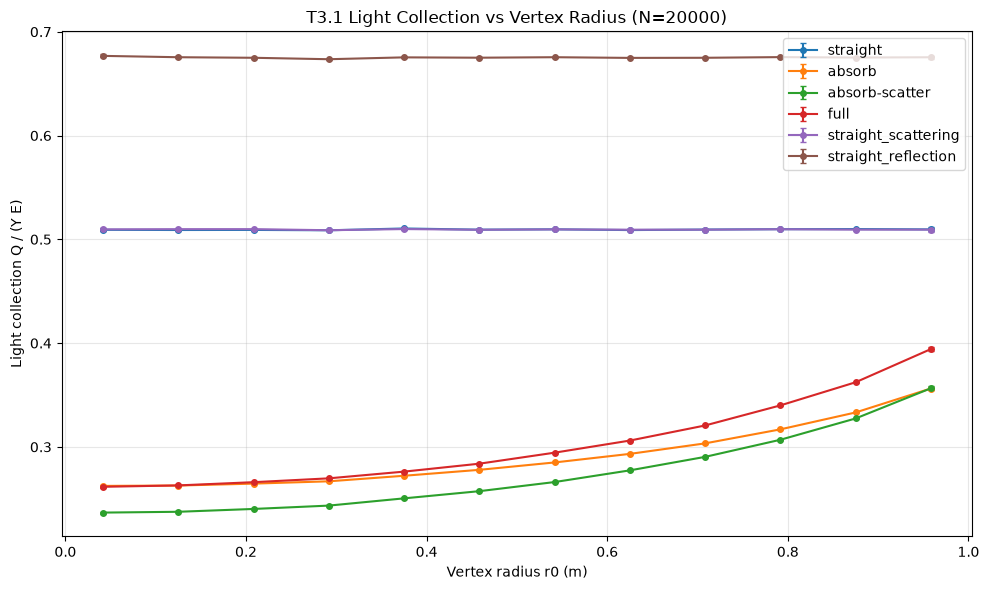

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

bins = np.linspace(0, 1, 13)
centers = (bins[:-1] + bins[1:]) / 2

for mode, d in datasets.items():

    # Extract true vertex coordinates（提取真实顶点坐标）
    x = d.truth.x
    y = d.truth.y
    r0 = np.sqrt(x**2 + y**2)

    # Calculate total detected charge（计算探测到的总电荷）
    Q = d.response.charge.sum(axis=1)
    E = d.truth.energy

    # Calculate light collection efficiency（计算光收集效率）
    Y = d.config.optics.light_yield
    efficiency = Q / (Y * E)

    # Calculate mean and SEM in radial bins（计算径向分箱的均值和标准误）
    means = []
    errors = []

    for i in range(len(bins) - 1):
        mask = (r0 >= bins[i]) & (r0 < bins[i+1])
        values = efficiency[mask]

        means.append(np.mean(values))
        errors.append(
            np.std(values, ddof=1) / np.sqrt(len(values))
        )

    ax.errorbar(
        centers,
        means,
        yerr=errors,
        marker="o",
        markersize=4,
        capsize=2,
        label=mode
    )

ax.set_xlabel("Vertex radius r0 (m)")
ax.set_ylabel("Light collection Q / (Y E)")
ax.set_title("T3.1 Light Collection vs Vertex Radius (N=20000)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig(OUT / "T3.1_light_collection.png", dpi=300)
plt.show()

straight              Median = -0.004 ns, P90 = 1.282 ns
absorb                Median = -0.006 ns, P90 = 1.279 ns
absorb-scatter        Median = 0.157 ns, P90 = 1.879 ns
full                  Median = 0.281 ns, P90 = 3.060 ns
straight_scattering   Median = 0.294 ns, P90 = 3.272 ns
straight_reflection   Median = 0.375 ns, P90 = 8.947 ns


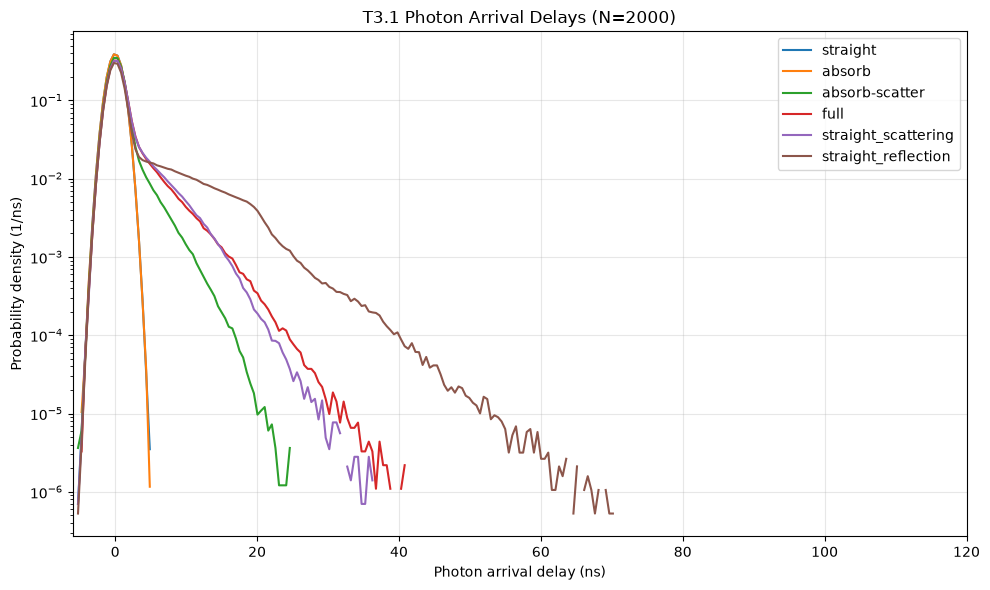

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

time_bins = np.linspace(-6, 120, 250)
centers = (time_bins[:-1] + time_bins[1:]) / 2

for mode in modes:
    # Load datasets with individual photon hits（加载包含单光子命中记录的数据）
    d = load(
        DATA / f"t3_{mode}_hits.h5",
        hits=True,
        tracks=False
    )

    hits = d.hits

    # Exclude noise hits（排除噪声命中）
    mask = ~hits.is_noise

    event_id = hits.event_id[mask].astype(int)
    sensor_id = hits.sensor[mask].astype(int)
    t = hits.time[mask]

    # Get the true event vertex and start time（获取真实事件顶点和起始时间）
    x0 = d.truth.x[event_id]
    y0 = d.truth.y[event_id]
    t0 = d.truth.t0[event_id]

    # Get sensor center coordinates（获取传感器中心坐标）
    sx = d.detector.sensor_x[sensor_id]
    sy = d.detector.sensor_y[sensor_id]

    # Calculate straight-line distance（计算直线传播距离）
    distance = np.sqrt(
        (sx - x0)**2 + (sy - y0)**2
    )

    cn = d.config.optics.speed_of_light

    # Calculate photon arrival delays（计算光子到达时间延迟）
    delay = t - t0 - distance / cn

    # Calculate probability density（计算概率密度）
    counts, _ = np.histogram(delay, bins=time_bins)  #统计每个时间区间的光子数
    density = counts / (len(delay) * np.diff(time_bins))  #np.diff() 是 NumPy 中用来计算数组中相邻两个元素之差的函数，这里是数组除以数组

    ax.plot(
        centers,
        np.where(density > 0, density, np.nan),
        label=mode
    )

    print(
        f"{mode:22s}"
        f"Median = {np.median(delay):.3f} ns, "
        f"P90 = {np.percentile(delay, 90):.3f} ns"
    )

ax.set_xlabel("Photon arrival delay (ns)")
ax.set_ylabel("Probability density (1/ns)")
ax.set_title("T3.1 Photon Arrival Delays (N=2000)")
ax.set_yscale("log")
ax.set_xlim(-6, 120)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig(OUT / "T3.1_arrival_delays.png", dpi=300)
plt.show()

In [14]:
from prob_reco_sbi.flash import sensor_edges

# Load fixed-vertex simulation data（加载固定顶点模拟数据）
d32 = load(DATA / "t3_straight_vertex.h5")

x0 = d32.truth.x[0]
y0 = d32.truth.y[0]
E = d32.truth.energy[0]

geometry = d32.config.geometry
R = geometry.radius
Y = d32.config.optics.light_yield
epsilon = d32.config.readout.detection_efficiency

N_photons = round(Y * E)

print("Vertex:", x0, y0)
print("Energy:", E, "MeV")
print("Emitted photons:", N_photons)
print("Events:", len(d32.truth.x))

Vertex: 0.5 0.2
Energy: 2.0 MeV
Emitted photons: 2000
Events: 1000


In [15]:
# Get sensor arc boundaries（获取传感器弧段边界）
edges = sensor_edges(geometry)

edge_x = R * np.cos(edges)
edge_y = R * np.sin(edges)

# Calculate viewing angles from the vertex（计算从顶点观察传感器的方向角）
beta = np.arctan2(
    edge_y - y0,
    edge_x - x0
)   #注意beta是一个二维数据，表示探测器的两个端点

delta_beta = np.mod(
    beta[:, 1] - beta[:, 0],
    2 * np.pi
)

# Calculate theoretical expected charge（计算理论预期电荷）
expected = N_photons * epsilon * delta_beta / (2 * np.pi)

# Calculate simulated mean, SEM and residuals（计算模拟均值、标准误和残差）
charge = d32.response.charge

simulated = charge.mean(axis=0)
sem = charge.std(axis=0, ddof=1) / np.sqrt(len(charge))

residual = simulated - expected


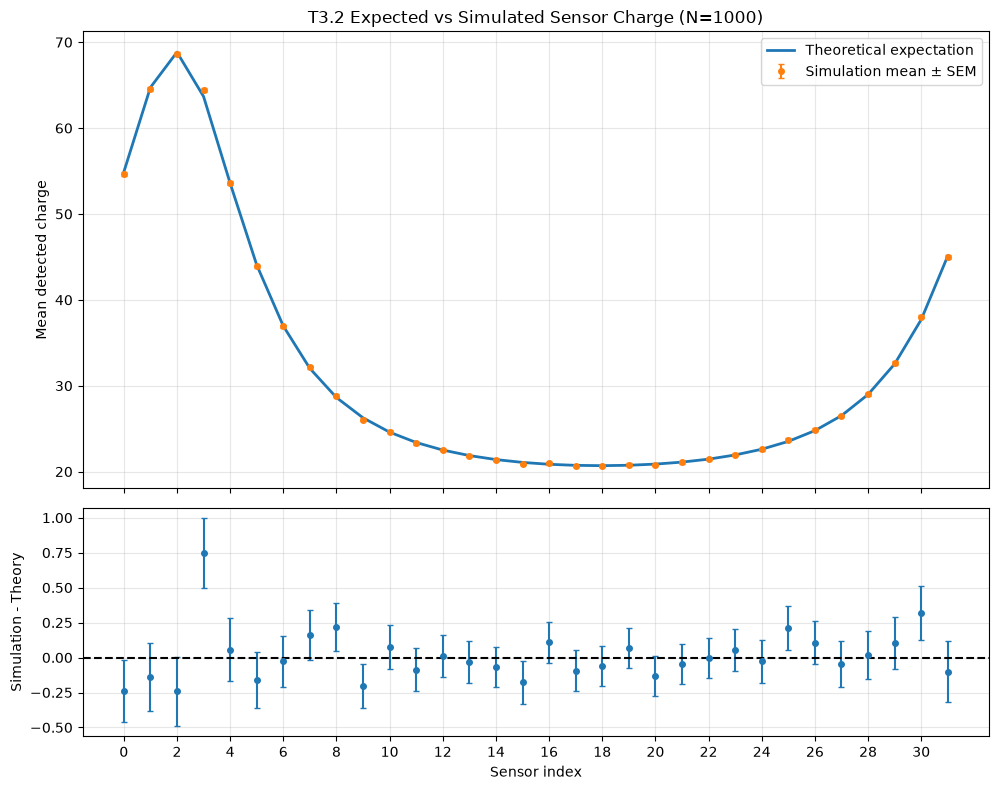

In [16]:
sensor_index = np.arange(geometry.n_sensors)

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

# Compare theoretical and simulated charges（比较理论与模拟电荷）
ax1.plot(
    sensor_index,
    expected,
    "-",
    linewidth=2,
    label="Theoretical expectation"
)

ax1.errorbar(
    sensor_index,
    simulated,
    yerr=sem,
    fmt="o",
    markersize=4,
    capsize=2,
    label="Simulation mean ± SEM"
)

ax1.set_ylabel("Mean detected charge")
ax1.set_title("T3.2 Expected vs Simulated Sensor Charge (N=1000)")
ax1.grid(alpha=0.3)
ax1.legend()

# Plot residuals with uncertainties（绘制残差及其统计误差）
ax2.errorbar(
    sensor_index,
    residual,
    yerr=sem,
    fmt="o",
    markersize=4,
    capsize=2
)

ax2.axhline(0, color="black", linestyle="--")
ax2.set_xlabel("Sensor index")
ax2.set_ylabel("Simulation - Theory")
ax2.set_xticks(np.arange(0, geometry.n_sensors, 2))
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / "T3.2_expected_vs_simulated.png", dpi=300)
plt.show()


In [17]:
# Calculate light collection efficiency（计算光收集效率）
def light_collection(d):
    Q = d.response.charge.sum(axis=1)
    E = d.truth.energy
    Y = d.config.optics.light_yield

    return Q / (Y * E)


collection33 = {}

for mode, d_mode in datasets.items():
    collection33[mode] = light_collection(d_mode)
    print(f"{mode:22s}: {collection33[mode].mean():.4f}")


# Compare individual optical processes（比较各光学过程的影响）
comparisons33 = {
    "Absorption": ("absorb", "straight"),
    "Scattering": ("straight_scattering", "straight"),
    "Reflection": ("straight_reflection", "straight"),
    "Scattering with absorption": ("absorb-scatter", "absorb"),
    "Reflection in full": ("full", "absorb-scatter")
}

print("\nChanges in light collection:")

for name, (mode1, mode0) in comparisons33.items():
    diff = collection33[mode1] - collection33[mode0]

    mean_diff = np.mean(diff)
    sem_diff = np.std(diff, ddof=1) / np.sqrt(len(diff))

    print(
        f"{name:28s}: "
        f"{100 * mean_diff:+.2f} ± {100 * sem_diff:.2f} percentage points"
    )

straight              : 0.5095
absorb                : 0.3071
absorb-scatter        : 0.2944
full                  : 0.3255
straight_scattering   : 0.5094
straight_reflection   : 0.6752

Changes in light collection:
Absorption                  : -20.25 ± 0.02 percentage points
Scattering                  : -0.01 ± 0.01 percentage points
Reflection                  : +16.56 ± 0.01 percentage points
Scattering with absorption  : -1.27 ± 0.01 percentage points
Reflection in full          : +3.11 ± 0.01 percentage points


straight               k = 509.46 PE/MeV
absorb                 k = 300.04 PE/MeV
absorb-scatter         k = 286.55 PE/MeV
full                   k = 317.42 PE/MeV
straight_scattering    k = 509.62 PE/MeV
straight_reflection    k = 675.08 PE/MeV


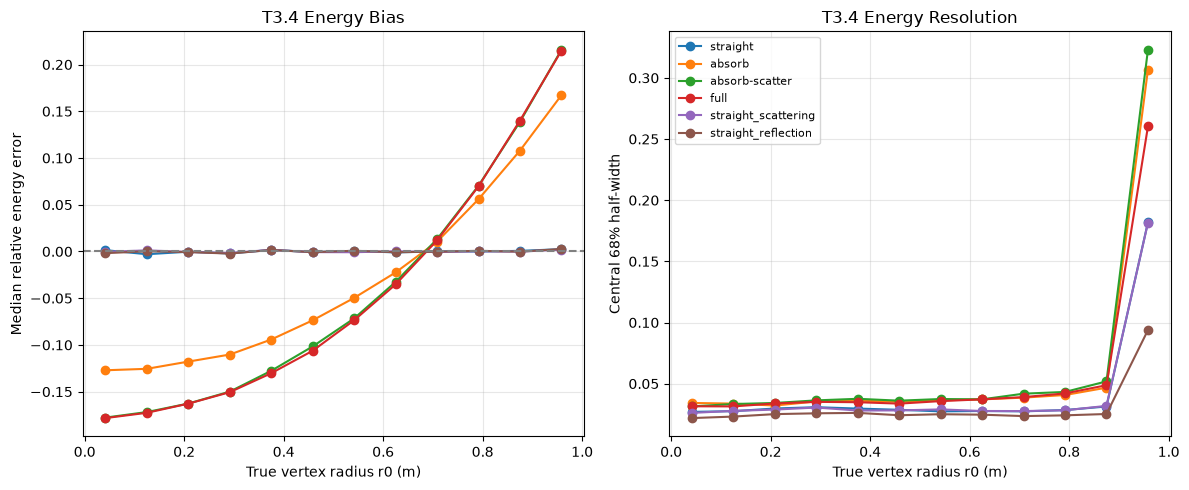

In [18]:
# Calculate robust statistics in radial bins（计算径向分箱内的稳健统计量）
def stats34(r, error, bins):
    bias, resolution, p68 = [], [], []

    for i in range(len(bins) - 1):
        mask = (r >= bins[i]) & (r < bins[i + 1])
        values = error[mask]
        values = values[np.isfinite(values)]

        if len(values) < 2:
            bias.append(np.nan)
            resolution.append(np.nan)
            p68.append(np.nan)
            continue

        p16, p50, p68_i, p84 = np.percentile(
            values, [16, 50, 68, 84]
        )

        bias.append(p50)
        resolution.append((p84 - p16) / 2)
        p68.append(p68_i)

    return np.array(bias), np.array(resolution), np.array(p68)


bins34 = np.linspace(0, 1, 13)
centers34 = (bins34[:-1] + bins34[1:]) / 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare energy reconstruction across six modes（比较六种模式的能量重建）
for mode34 in modes:
    d34 = datasets[mode34]

    Q34 = d34.response.charge.sum(axis=1)
    E34 = d34.truth.energy
    r34 = np.hypot(d34.truth.x, d34.truth.y)

    k34 = np.median(Q34 / E34)
    E_rec34 = Q34 / k34
    error34 = (E_rec34 - E34) / E34

    bias34, res34, _ = stats34(r34, error34, bins34)

    axes[0].plot(centers34, bias34, "o-", label=mode34)
    axes[1].plot(centers34, res34, "o-", label=mode34)

    print(f"{mode34:22s} k = {k34:.2f} PE/MeV")

axes[0].set_title("T3.4 Energy Bias")
axes[0].set_ylabel("Median relative energy error")
axes[0].axhline(0, color="gray", linestyle="--")

axes[1].set_title("T3.4 Energy Resolution")
axes[1].set_ylabel("Central 68% half-width")

for ax in axes:
    ax.set_xlabel("True vertex radius r0 (m)")
    ax.grid(alpha=0.3)

axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "T3.4_energy.png", dpi=300)
plt.show()

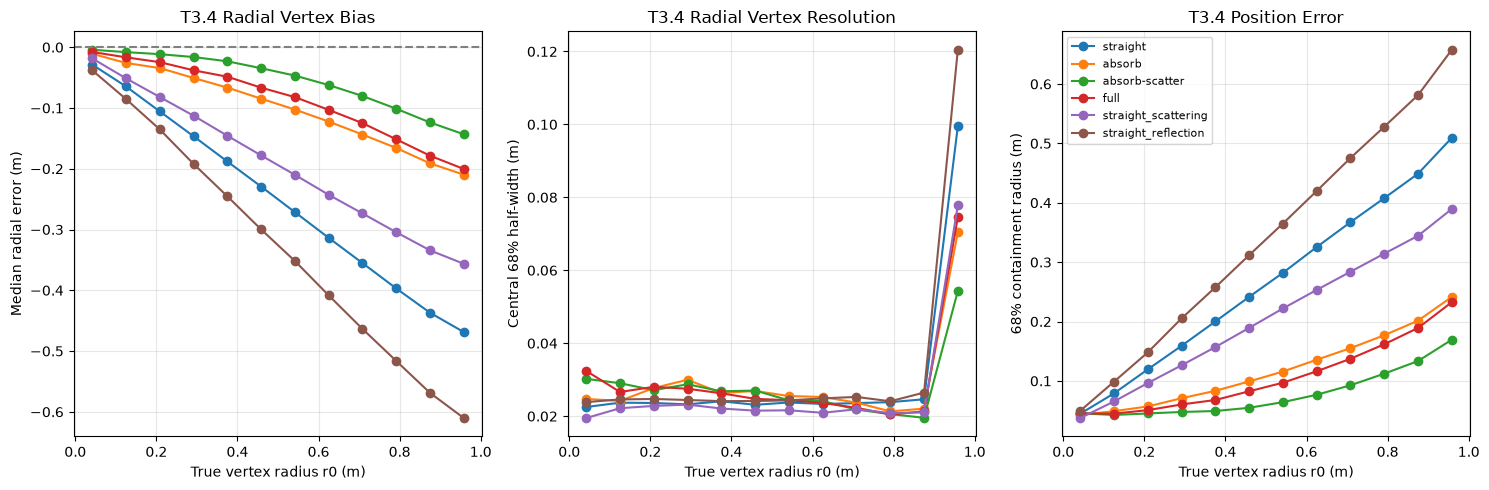

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Compare vertex reconstruction across six modes（比较六种模式的顶点重建）
for mode34 in modes:
    d34 = datasets[mode34]

    charge34 = d34.response.charge
    Q34 = charge34.sum(axis=1).astype(float)
    Q_safe34 = np.where(Q34 > 0, Q34, np.nan)

    x34 = d34.truth.x
    y34 = d34.truth.y
    r34 = np.hypot(x34, y34)

    # Reconstruct the charge-weighted barycentre（重建电荷加权重心）
    x_rec34 = (charge34 @ d34.detector.sensor_x) / Q_safe34
    y_rec34 = (charge34 @ d34.detector.sensor_y) / Q_safe34

    dx34 = x_rec34 - x34
    dy34 = y_rec34 - y34

    # Calculate radial and 2D position errors（计算径向及二维位置误差）
    radial_error34 = np.divide(
        dx34 * x34 + dy34 * y34,
        r34,
        out=np.full_like(r34, np.nan),
        where=r34 > 0
    )

    distance34 = np.hypot(dx34, dy34)

    bias34, res34, _ = stats34(r34, radial_error34, bins34)
    _, _, p68_34 = stats34(r34, distance34, bins34)

    axes[0].plot(centers34, bias34, "o-", label=mode34)
    axes[1].plot(centers34, res34, "o-", label=mode34)
    axes[2].plot(centers34, p68_34, "o-", label=mode34)

axes[0].set_title("T3.4 Radial Vertex Bias")
axes[0].set_ylabel("Median radial error (m)")
axes[0].axhline(0, color="gray", linestyle="--")

axes[1].set_title("T3.4 Radial Vertex Resolution")
axes[1].set_ylabel("Central 68% half-width (m)")

axes[2].set_title("T3.4 Position Error")
axes[2].set_ylabel("68% containment radius (m)")

for ax in axes:
    ax.set_xlabel("True vertex radius r0 (m)")
    ax.grid(alpha=0.3)

axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "T3.4_vertex.png", dpi=300)
plt.show()